In [33]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("retail_sales_sample.csv")

In [34]:
print("Dataset size:", df.shape)

print("\nColumn types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nNumeric column statistics:")
display(df.describe().T)

print("\nMedian:")
display(df.median(numeric_only=True))

print("\nMode:")
display(df.mode().iloc[0])

Dataset size: (1200, 11)

Column types:
Date                  str
Customer_ID           str
Customer_Age        int64
Gender                str
Product               str
Category              str
Quantity            int64
Unit_Price        float64
Total_Amount      float64
Payment_Method        str
City                  str
dtype: object

Missing values:
Date              0
Customer_ID       0
Customer_Age      0
Gender            0
Product           0
Category          0
Quantity          0
Unit_Price        0
Total_Amount      0
Payment_Method    0
City              0
dtype: int64

Numeric column statistics:


,count,mean,std,min,25%,50%,75%,max
Customer_Age,1200.0,43.208333,15.088394,18.0,30.00,42.00,56.0000,70.0
Quantity,1200.0,2.033333,1.129876,1.0,1.00,2.00,3.0000,6.0
Unit_Price,1200.0,37.643158,29.995250,8.5,14.99,19.99,54.0000,129.0
Total_Amount,1200.0,76.480458,82.034684,8.5,24.99,48.00,99.9525,645.0



Median:


Customer_Age    42.00
Quantity         2.00
Unit_Price      19.99
Total_Amount    48.00
dtype: float64


Mode:


Date              2025-03-08
Customer_ID            C0072
Customer_Age            42.0
Gender                Female
Product              T-Shirt
Category            Clothing
Quantity                 1.0
Unit_Price             19.99
Total_Amount           59.99
Payment_Method          Card
City              Coimbatore
Name: 0, dtype: object

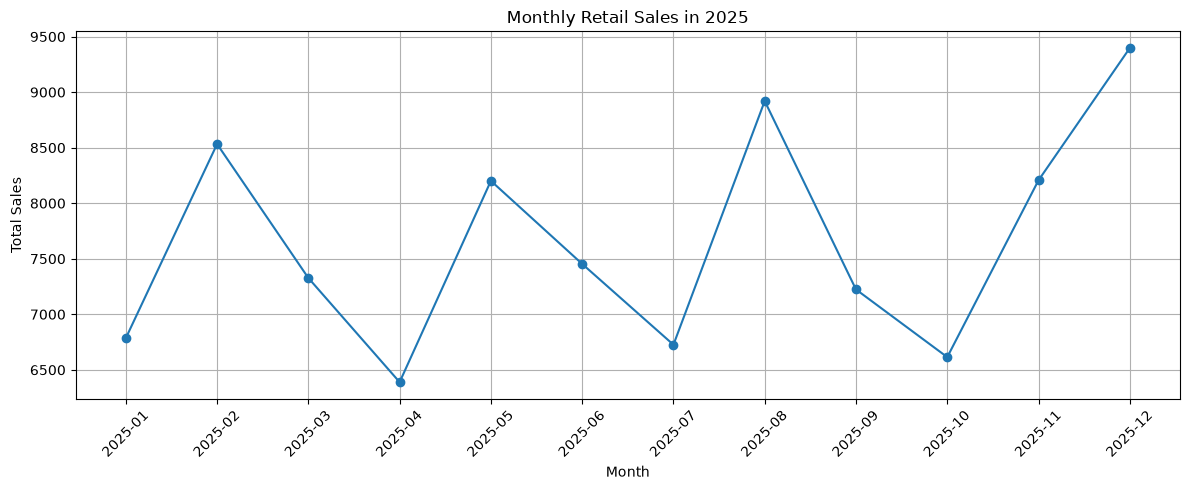

In [35]:
df["Date"] = pd.to_datetime(df["Date"])

monthly_sales = (
    df.groupby(df["Date"].dt.to_period("M"))["Total_Amount"]
      .sum()
)

monthly_sales.index = monthly_sales.index.astype(str)

plt.figure(figsize=(12, 5))
plt.plot(monthly_sales.index, monthly_sales.values, marker="o")
plt.title("Monthly Retail Sales in 2025")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

### Monthly Sales Observation
Sales were highest in December, followed by August and February. April had the lowest sales. Monthly sales fluctuate rather than increasing steadily. This is a synthetic sample dataset, so these patterns are for practice only.

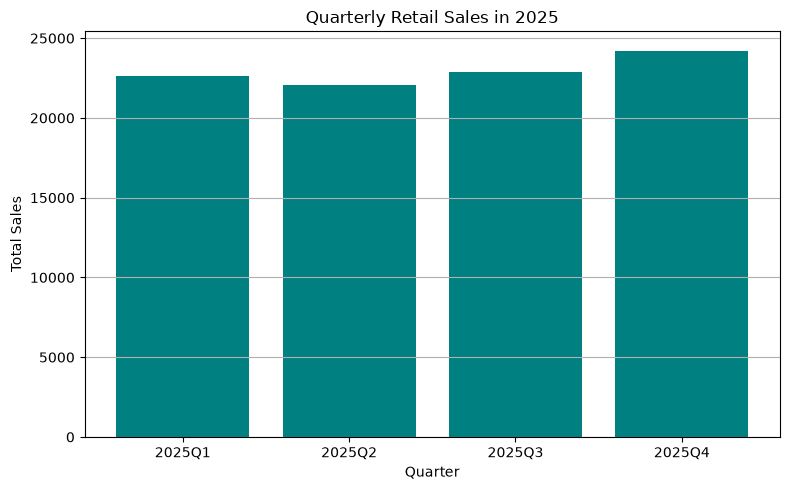

In [36]:
quarterly_sales = df.groupby(
    df["Date"].dt.to_period("Q")
)["Total_Amount"].sum()

quarterly_sales.index = quarterly_sales.index.astype(str)

plt.figure(figsize=(8, 5))
plt.bar(quarterly_sales.index, quarterly_sales.values, color="teal")
plt.title("Quarterly Retail Sales in 2025")
plt.xlabel("Quarter")
plt.ylabel("Total Sales")
plt.grid(axis="y")
plt.tight_layout()
plt.show()

### Quarterly Sales Observation
Quarter 4 had the highest total sales, while Quarter 2 had the lowest. Sales increased from Quarter 2 through Quarter 4. This is a synthetic sample dataset, so these patterns are for practice only.

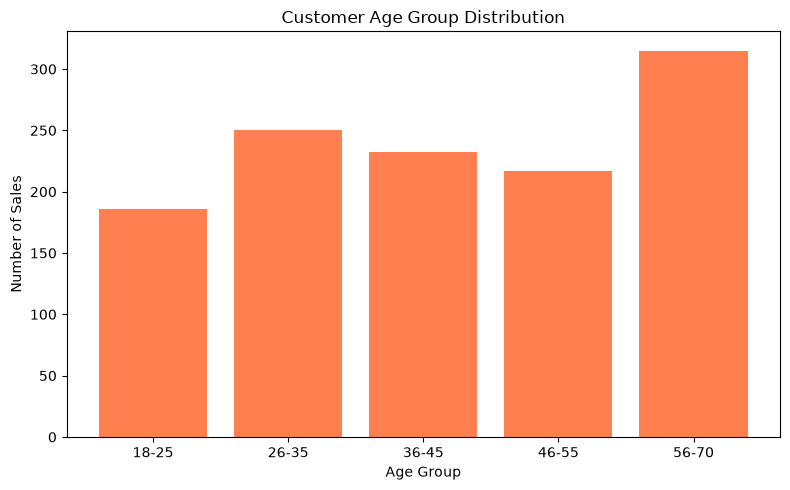

In [37]:
age_bins = [17, 25, 35, 45, 55, 71]
age_labels = ["18-25", "26-35", "36-45", "46-55", "56-70"]

df["Age_Group"] = pd.cut(
    df["Customer_Age"],
    bins=age_bins,
    labels=age_labels
)

age_counts = df["Age_Group"].value_counts().sort_index()

plt.figure(figsize=(8, 5))
plt.bar(age_counts.index.astype(str), age_counts.values, color="coral")
plt.title("Customer Age Group Distribution")
plt.xlabel("Age Group")
plt.ylabel("Number of Sales")
plt.tight_layout()
plt.show()

### Customer Age Observation
The 56-70 age group has the most sales records, while the 18-25 group has the fewest. This describes the sample's transaction records, not necessarily unique customers.

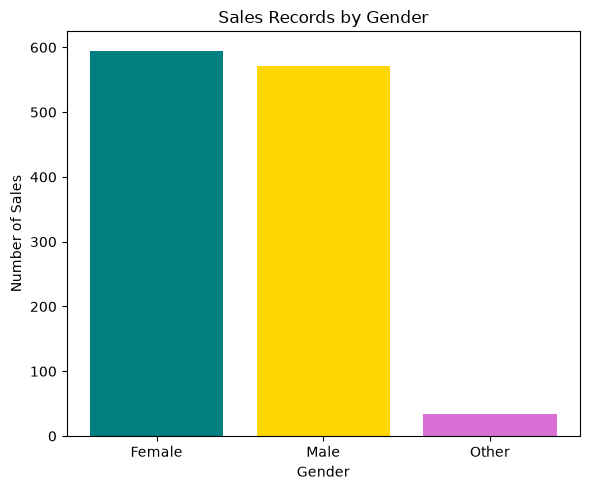

In [38]:
gender_counts = df["Gender"].value_counts()

plt.figure(figsize=(6, 5))
plt.bar(gender_counts.index, gender_counts.values, color=["teal", "gold", "orchid"])
plt.title("Sales Records by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Sales")
plt.tight_layout()
plt.show()

### Gender Observation
Female and male sales records are fairly similar in this sample, while the Other category has fewer records. These counts represent transactions, not necessarily unique customers.

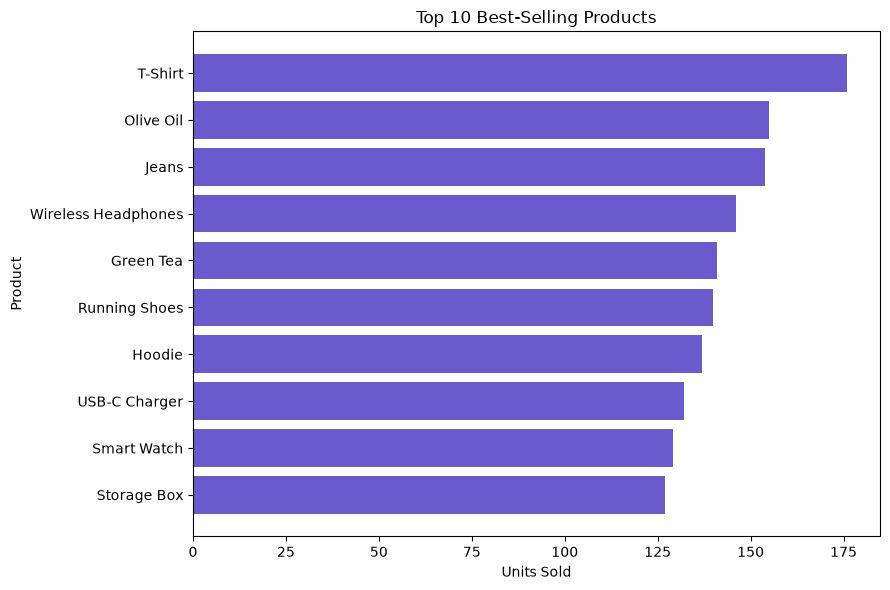

In [39]:
top_products = (
    df.groupby("Product")["Quantity"]
      .sum()
      .sort_values(ascending=False)
      .head(10)
      .sort_values()
)

plt.figure(figsize=(9, 6))
plt.barh(top_products.index, top_products.values, color="slateblue")
plt.title("Top 10 Best-Selling Products")
plt.xlabel("Units Sold")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

### Product Sales Observation
[Product name] had the highest number of units sold among the top 10 products. This is based on quantity sold in the synthetic sample dataset.

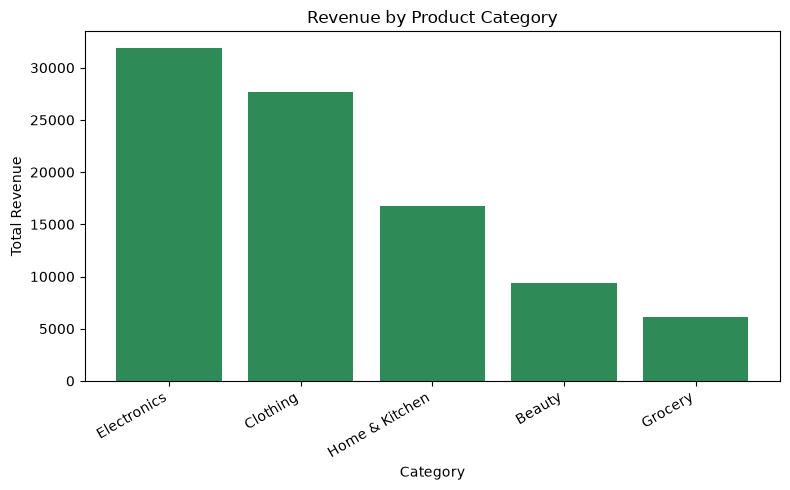

In [40]:
category_revenue = (
    df.groupby("Category")["Total_Amount"]
      .sum()
      .sort_values(ascending=False)
)

plt.figure(figsize=(8, 5))
plt.bar(category_revenue.index, category_revenue.values, color="seagreen")
plt.title("Revenue by Product Category")
plt.xlabel("Category")
plt.ylabel("Total Revenue")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

### Category Revenue Observation
Electronics generated the highest revenue in this sample, while Grocery generated the lowest. The business could review product mix and promotion strategies for lower-revenue categories. This is synthetic practice data.

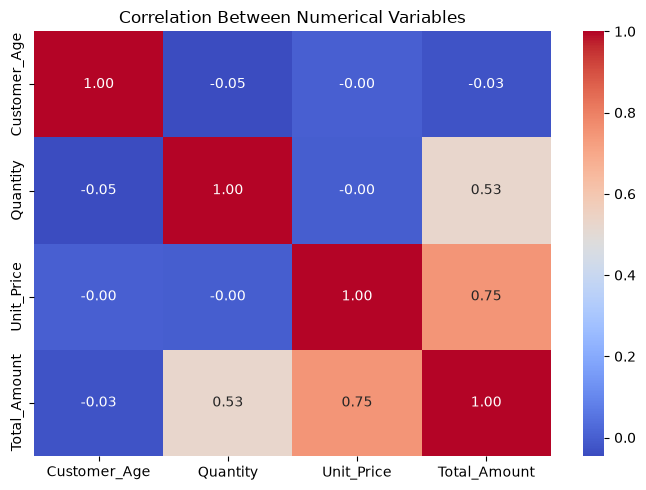

In [41]:
numeric_columns = ["Customer_Age", "Quantity", "Unit_Price", "Total_Amount"]
correlation = df[numeric_columns].corr()

plt.figure(figsize=(7, 5))
sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Between Numerical Variables")
plt.tight_layout()
plt.show()

### Correlation Observation
Total amount has a stronger positive correlation with unit price (0.75) and a moderate positive correlation with quantity (0.53). Customer age has almost no correlation with the other numerical variables. Correlation does not prove causation; total amount is also calculated from unit price and quantity.

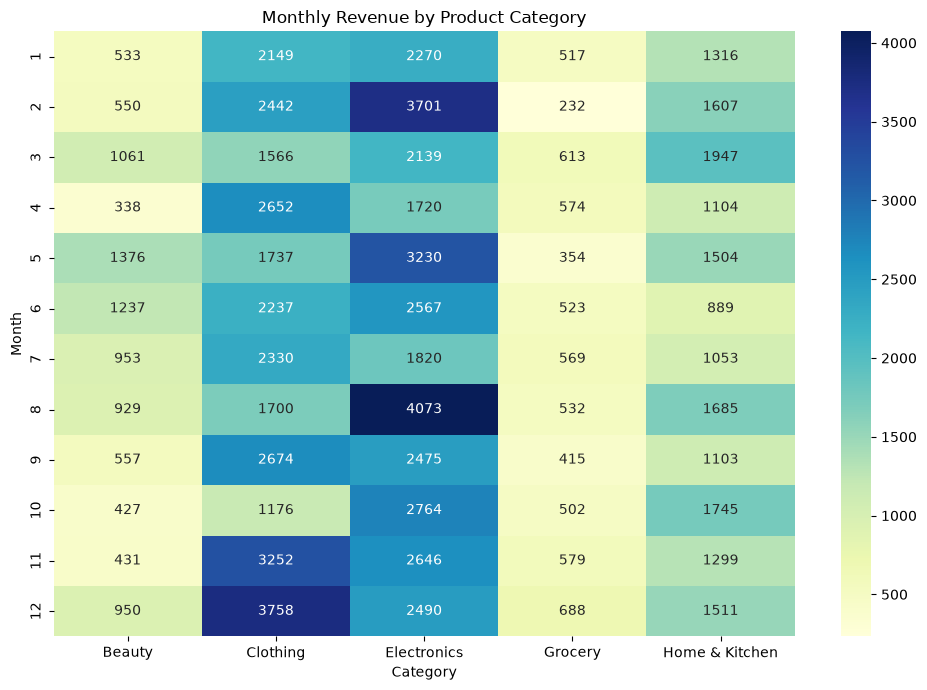

In [42]:
df["Date"] = pd.to_datetime(df["Date"])

month_category_sales = df.assign(
    Month=df["Date"].dt.month
).pivot_table(
    index="Month",
    columns="Category",
    values="Total_Amount",
    aggfunc="sum"
)

plt.figure(figsize=(10, 7))
sns.heatmap(month_category_sales, cmap="YlGnBu", annot=True, fmt=".0f")
plt.title("Monthly Revenue by Product Category")
plt.xlabel("Category")
plt.ylabel("Month")
plt.tight_layout()
plt.show()

### Additional Visualization Observation
The highest monthly category revenue appears in [month and category], while the lowest appears in [month and category]. This pattern may help with monthly inventory planning. The dataset is synthetic and used for practice.

## Conclusion and Business Recommendations
1. Electronics generated the highest revenue in this sample. Keep popular electronics products in stock and monitor inventory before busy periods.
2. Grocery generated the lowest revenue. Test small bundles or limited promotions, then compare sales before continuing them.
3. Quarter 4 had the highest sales. Plan stock and promotional campaigns ahead of that period.
4. The age-group counts describe transactions, not unique customers. Use real customer data before making age-targeted marketing decisions.